# Real vs AI-Generated Face Detection

This notebook trains and compares five binary classifiers that tell real face photos from AI-generated ones: an MLP, a small CNN, the same CNN with data augmentation, MobileNetV3Small with a frozen backbone, and MobileNetV3Small fine-tuned. The best model is used in the Gradio game in `game/`.

**Dataset:** real and AI-generated face images, resized to 128×128 RGB. 600 images per class are used for training and validation (1,020 train, 180 validation), plus a separate fixed test set of 150 images per class. Every split is balanced.

**Sections**

| Part | Topic |
|---|---|
| 1 | Dataset setup and exploration |
| 2 | MLP baseline |
| 3 | CNN baseline |
| 4 | CNN with data augmentation, BatchNorm diagnosis |
| 5 | Transfer learning with MobileNetV3Small (frozen backbone, two heads compared) |
| 6 | Fine-tuning the last 30 backbone layers |
| 7 | Model comparison and analysis |
| 8 | Interactive game (human vs model) |


---
### Summary of results (test set, 300 images)

| Model | Trainable parameters | Best val acc | Test acc |
|---|---|---|---|
| MLP | 6,299,905 | 0.706 | 0.667 |
| CNN (baseline) | 30,225 | 0.589 | 0.670 |
| CNN + augmentation | 30,225 | 0.578 | 0.607 |
| MobileNetV3Small, frozen (Head B) | 73,985 | 0.756 | 0.723 |
| **MobileNetV3Small, fine-tuned** | 642,785 | **0.778** | **0.763** |

**Best model:** fine-tuned MobileNetV3Small (76.3% test accuracy). It is used in the Part 8 game.

### How to read this notebook
* Parts 1 to 3 (data loading, MLP and CNN baselines) come from a provided template, unchanged. I added short notes after each part describing what the outputs show.
* Parts 4 to 8 are my work. Each code cell is preceded by a short explanation of what it does and why, and followed by the key observations.
* All numbers in the text come from one complete, in-order run of this notebook (Colab, CPU runtime).
* Noise level to keep in mind: with 180 validation images, one standard error of an accuracy near 0.7 is about ±3.5 points; with 300 test images it is about ±2.5 points. Small differences between models are within noise.
---

## Setup: Import Required Libraries

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import Adam

print(f"TensorFlow version: {tf.__version__}")
print(f"Running on: {'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'}")

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

TensorFlow version: 2.20.0
Running on: CPU


## Part 1: Dataset setup and preprocessing

Downloads the face dataset, resizes every image to 128×128 RGB and scales pixels to [0, 1]. The data is split into a separate test set of 300 images (150 per class) and the remaining images into 85% training and 15% validation, stratified by class.


In [ ]:
# ============================================================
# Part 1 - Dataset download
# ============================================================

!pip install -q gdown

import gdown
import os
import zipfile
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

# Dataset archive (Google Drive)
FILE_ID = "154rbZmY2HI0qVbBVEJ1nbvoHDJmY7fQX"
url = f"https://drive.google.com/uc?id={FILE_ID}"

print("📥 Downloading dataset...")
output_path = '/content/real_and_AI.zip'

try:
    gdown.download(url, output_path, quiet=False)

    print("\n📦 Extracting files...")
    with zipfile.ZipFile(output_path, 'r') as zip_ref:
        zip_ref.extractall('/content/')

    # Clean up zip file
    os.remove(output_path)

    # Verify the download
    real_count = len(os.listdir('/content/real_and_AI/training_real'))
    fake_count = len(os.listdir('/content/real_and_AI/training_AI'))

    print("\n✅ Dataset successfully loaded!")
    print(f"   • Real faces: {real_count} images")
    print(f"   • AI faces: {fake_count} images")

except Exception as e:
    print(f"❌ Error downloading dataset: {e}")
    print("Check the file ID and your internet connection.")




📥 Downloading dataset...


Downloading...
From (original): https://drive.google.com/uc?id=154rbZmY2HI0qVbBVEJ1nbvoHDJmY7fQX
From (redirected): https://drive.google.com/uc?id=154rbZmY2HI0qVbBVEJ1nbvoHDJmY7fQX&confirm=t&uuid=f1f16107-ec35-4e0d-a5db-8df239104139
To: /content/real_and_AI.zip
100%|██████████| 66.9M/66.9M [00:00<00:00, 146MB/s]



📦 Extracting files...

✅ Dataset successfully loaded!
   • Real faces: 1001 images
   • AI faces: 1001 images


In [ ]:
# ============================================================
# Load images into arrays
# ============================================================
print("\n" + "="*50)
print("Loading images into arrays...")

def load_images_from_folder(folder_path, label, max_images=600, target_size=(128, 128)):
    """
    Load images from a folder and assign a label.
    Images are loaded as RGB (3 channels) and normalized to [0, 1].
    """
    images, labels = [], []

    # Filter out hidden files (e.g. .DS_Store) and non-image files
    valid_extensions = ('.jpg', '.jpeg')
    image_files = [
        f for f in sorted(os.listdir(folder_path))
        if not f.startswith('.') and f.lower().endswith(valid_extensions)
    ][:max_images]

    for img_file in image_files:
        img_path = os.path.join(folder_path, img_file)
        try:
            img = Image.open(img_path)
            img = img.resize(target_size)
            img_array = np.array(img) / 255.0  # Normalize [0, 1]
            images.append(img_array)
            labels.append(label)
        except Exception as e:
            print(f"⚠️ Error loading {img_file}: {e}")

    return np.array(images), np.array(labels)

# Paths
data_path = '/content/real_and_AI/'

# Training images
print("Loading real training images...")
real_images, real_labels = load_images_from_folder(
    os.path.join(data_path, 'training_real'),
    label=1
)
print("Loading AI-generated training images...")
fake_images, fake_labels = load_images_from_folder(
    os.path.join(data_path, 'training_AI'),
    label=0
)

# Combine training
X = np.concatenate([real_images, fake_images])
y = np.concatenate([real_labels, fake_labels])

# Test images (new fixed folders)
print("Loading real test images...")
test_real_images, test_real_labels = load_images_from_folder(
    os.path.join(data_path, 'test_real'),
    label=1
)
print("Loading fake test images...")
test_fake_images, test_fake_labels = load_images_from_folder(
    os.path.join(data_path, 'test_AI'),
    label=0
)

X_test = np.concatenate([test_real_images, test_fake_images])
y_test = np.concatenate([test_real_labels, test_fake_labels])

# Reshape
X = X.reshape(X.shape[0], 128, 128, 3)
X_test = X_test.reshape(X_test.shape[0], 128, 128, 3)

# Split training further into train/val (70/15/15 overall)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

print(f"\n✅ Dataset ready for training!")
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(f"Image shape: {X_train[0].shape}")
print(f"Real images: {np.sum(y == 1)} | Fake images: {np.sum(y == 0)}")


Loading images into arrays...
Loading real training images...
Loading AI-generated training images...
Loading real test images...
Loading fake test images...

✅ Dataset ready for training!
Train: 1020 | Val: 180 | Test: 300
Image shape: (128, 128, 3)
Real images: 600 | Fake images: 600


### Data exploration

Shapes of each split, sample real and AI faces side by side, the average face of each class, and the class balance.


Shapes:
 X_train: (1020, 128, 128, 3)  y_train: (1020,)
 X_val:   (180, 128, 128, 3)  y_val:   (180,)
 X_test:  (300, 128, 128, 3)  y_test:  (300,)



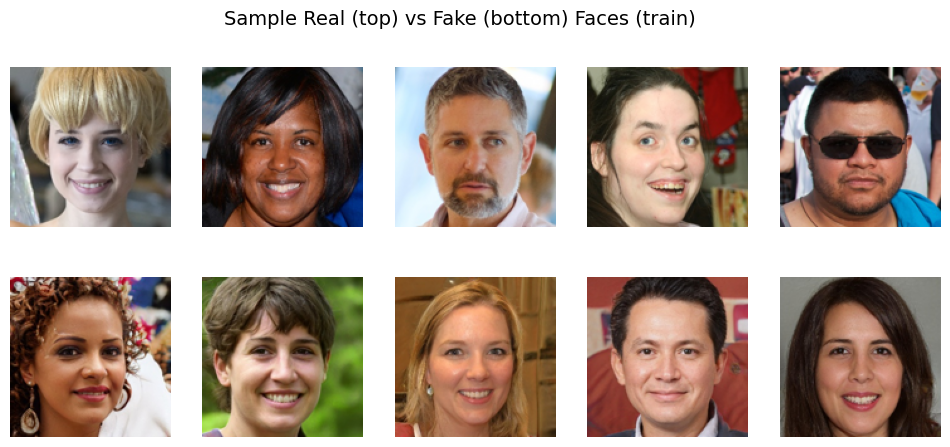

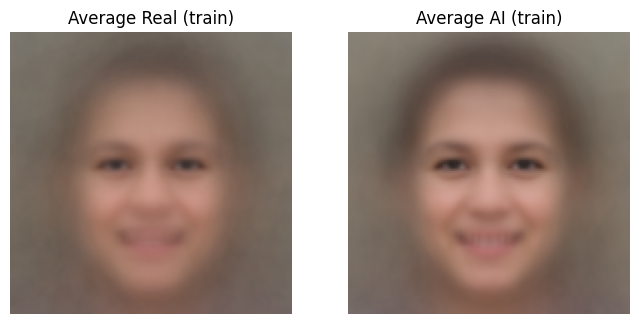

📊 Dataset statistics:
 Train  - Real: 510  AI: 510
 Val    - Real: 90  AI: 90
 Test   - Real: 150  AI: 150


In [ ]:
# ============================================================
# Part 1 - Data Exploration
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Quick sanity checks
print("Shapes:")
print(" X_train:", X_train.shape, " y_train:", y_train.shape)
print(" X_val:  ", X_val.shape, " y_val:  ", y_val.shape)
print(" X_test: ", X_test.shape, " y_test: ", y_test.shape)
print()

# Show sample real vs fake images from training set
def pick_n_per_class(X, y, n=5, cls=1):
    idxs = np.where(y == cls)[0]
    sel = np.random.choice(idxs, size=min(n, len(idxs)), replace=False)
    return X[sel]

np.random.seed(42)
real_samples = pick_n_per_class(X_test, y_test, n=5, cls=1)
fake_samples = pick_n_per_class(X_test, y_test, n=5, cls=0)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Sample Real (top) vs Fake (bottom) Faces (train)", fontsize=14)

for i in range(5):
    axes[0, i].imshow(real_samples[i].reshape(128, 128, 3))
    axes[0, i].axis("off")
    axes[1, i].imshow(fake_samples[i].reshape(128, 128, 3))
    axes[1, i].axis("off")
plt.show()

# Compute average faces (train)
avg_real = X_train[y_train == 1].mean(axis=0)
avg_fake = X_train[y_train == 0].mean(axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
ax1.imshow(avg_real.reshape(128, 128, 3)); ax1.set_title("Average Real (train)"); ax1.axis("off")
ax2.imshow(avg_fake.reshape(128, 128, 3)); ax2.set_title("Average AI (train)"); ax2.axis("off")
plt.show()

# Basic stats
print("📊 Dataset statistics:")
print(" Train  - Real:", np.sum(y_train==1), " AI:", np.sum(y_train==0))
print(" Val    - Real:", np.sum(y_val==1),   " AI:", np.sum(y_val==0))
print(" Test   - Real:", np.sum(y_test==1),  " AI:", np.sum(y_test==0))


**Observations (data exploration)**
* All splits are balanced (510/510 train, 90/90 val, 150/150 test), so 50% accuracy is the coin-flip baseline.
* The sample real and AI faces are hard to tell apart by eye.
* The **average AI face is sharper** than the average real face (eyes, mouth and face outline are well defined). This means generated faces are more consistently aligned, while real photos vary more in position and zoom.
* The average real face shows a faint grid texture, likely from JPEG 8×8 block compression.
* Risk: a model could learn these shortcuts (alignment, compression) instead of genuine generation artifacts.

## Part 2: Multi-layer perceptron (MLP) baseline

Flatten, Dense(128, ReLU), Dense(64, ReLU), Dense(1, sigmoid). Adam (learning rate 0.001), binary cross-entropy, 20 epochs, batch size 32. An MLP treats the image as a flat vector and ignores the spatial layout, so it serves as the simplest baseline.


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │     6,291,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,299,905 (24.03 MB)

 Trainable params: 6,299,905 (24.03 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 12s 249ms/step - accuracy: 0.5049 - loss: 2.5953 - val_accuracy: 0.5111 - val_loss: 1.6706
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.5333 - loss: 1.1695 - val_accuracy: 0.5167 - val_loss: 1.2158
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 120ms/step - accuracy: 0.5529 - loss: 1.0611 - val_accuracy: 0.6556 - val_loss: 0.6330
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 100ms/step - accuracy: 0.6255 - loss: 0.7742 - val_accuracy: 0.5222 - val_loss: 1.0644
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - accuracy: 0.6039 - loss: 0.8232 - val_accuracy: 0.5889 - val_loss: 0.7464
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.6284 - loss: 0.7761 - val_accuracy: 0.6389 - val_loss: 0.6438
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 123ms/step - accuracy: 0.6559 - loss: 0.6823 - val_accuracy: 0.6333 - val_loss: 0.6821
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step - accuracy: 0.6873 - loss: 0.6089 - val_accuracy

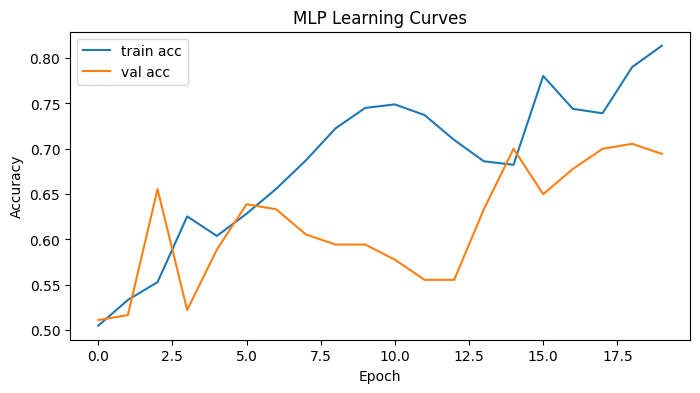

MLP test accuracy: 0.6667


In [ ]:
# ============================================================
# Part 2 - Multi-Layer Perceptron
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Input # Import Input
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import numpy as np

tf.random.set_seed(42)

mlp_model = Sequential([
    Input(shape=(128, 128, 3)),  # Use Input layer for input shape
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

mlp_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print(mlp_model.summary())

history_mlp = mlp_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=1
)

# Best validation accuracy and epoch
best_val_acc_mlp = np.max(history_mlp.history['val_accuracy'])
best_epoch_mlp = np.argmax(history_mlp.history['val_accuracy']) + 1
print(f"MLP best val acc: {best_val_acc_mlp:.4f} at epoch {best_epoch_mlp}")

# Plot learning curves
plt.figure(figsize=(8,4))
plt.plot(history_mlp.history['accuracy'], label='train acc')
plt.plot(history_mlp.history['val_accuracy'], label='val acc')
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("MLP Learning Curves")
plt.show()

# Evaluate on test set
mlp_test_loss, mlp_test_acc = mlp_model.evaluate(X_test, y_test, verbose=0)
print(f"MLP test accuracy: {mlp_test_acc:.4f}")

**Observations (MLP)**
* Best validation accuracy 0.706 at epoch 19. The test accuracy (0.667) comes from the **last** epoch, because this cell has no checkpoint.
* Validation accuracy jumps between about 0.52 and 0.71 while train accuracy reaches about 0.81: the model overfits.
* Reason: 6.3M parameters (99.9% in the first Dense layer) for only 1,020 training images, and `Flatten` discards the spatial layout of the image.

## Part 3: Convolutional neural network (CNN) baseline

Three Conv2D, BatchNorm, ReLU, MaxPooling and Dropout blocks (16, 32, 64 filters), then GlobalAveragePooling2D, Dense(96) and a sigmoid output. Adam (learning rate 0.001), 25 epochs, checkpoint on validation loss. Weight sharing and global pooling keep the parameter count small.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_66 (Activation)      │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_67 (Activation)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_68 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 96)             │         6,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 96)             │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_69 (Activation)      │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │            97 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,641 (119.69 KB)

 Trainable params: 30,225 (118.07 KB)

 Non-trainable params: 416 (1.62 KB)

Epoch 1/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 867ms/step - accuracy: 0.5222 - loss: 0.7658
Epoch 1: val_loss improved from None to 0.69331, saving model to best_cnn_baseline.keras

Epoch 1: finished saving model to best_cnn_baseline.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 34s 927ms/step - accuracy: 0.5265 - loss: 0.7627 - val_accuracy: 0.5000 - val_loss: 0.6933
Epoch 2/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 851ms/step - accuracy: 0.5459 - loss: 0.7135
Epoch 2: val_loss did not improve from 0.69331
32/32 ━━━━━━━━━━━━━━━━━━━━ 39s 893ms/step - accuracy: 0.5451 - loss: 0.7140 - val_accuracy: 0.5000 - val_loss: 0.6952
Epoch 3/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 830ms/step - accuracy: 0.5595 - loss: 0.7227
Epoch 3: val_loss did not improve from 0.69331
32/32 ━━━━━━━━━━━━━━━━━━━━ 40s 872ms/step - accuracy: 0.5735 - loss: 0.7124 - val_accuracy: 0.5000 - val_loss: 0.7028
Epoch 4/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 855ms/step - accuracy: 0.5973 - loss: 0.6944
Epoch 4: val_loss did not improve from 0.69331
32/32 ━━━━━━━

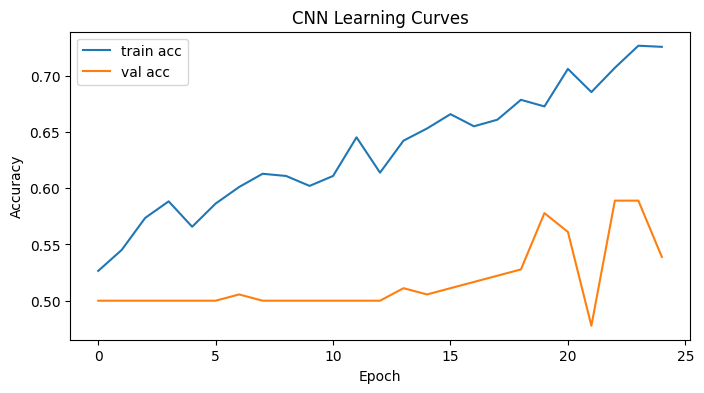

In [ ]:
# ============================================================
# Part 3 - CNN (Baseline)
# ============================================================

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, BatchNormalization, Activation, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt

# ---- CNN baseline ----

cnn_model = Sequential([
    # First conv block
    Conv2D(16, (3,3), padding='same', use_bias=False, input_shape=(128,128,3)),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.15),

    # Second conv block
    Conv2D(32, (3,3), padding='same', use_bias=False),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.15),

    # Third conv block
    Conv2D(64, (3,3), padding='same', use_bias=False),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.15),

    GlobalAveragePooling2D(),

    Dense(96),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.25),  # ← Increased final dropout

    Dense(1, activation='sigmoid')
])

cnn_model.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
cnn_model.summary()

checkpoint_cnn_path = "best_cnn_baseline.keras"
checkpoint_cnn = ModelCheckpoint(checkpoint_cnn_path, monitor='val_loss', save_best_only=True, mode='min', verbose=1)

history_cnn = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[checkpoint_cnn],
    verbose=1
)

best_val_acc_cnn = np.max(history_cnn.history['val_accuracy'])
best_val_loss_cnn = np.min(history_cnn.history['val_loss'])
best_epoch_cnn = np.argmin(history_cnn.history['val_loss']) + 1
print(f">> CNN baseline best val acc: {best_val_acc_cnn:.4f} at epoch {best_epoch_cnn}")

# Load best baseline cnn and evaluate on test set
best_cnn = load_model(checkpoint_cnn_path)
cnn_test_loss, cnn_test_acc = best_cnn.evaluate(X_test, y_test, verbose=0)
print(f">> CNN baseline test acc (best model): {cnn_test_acc:.4f}")

# Plot learning curves
plt.figure(figsize=(8,4))
plt.plot(history_cnn.history['accuracy'], label='train acc')
plt.plot(history_cnn.history['val_accuracy'], label='val acc')
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("CNN Learning Curves")
plt.show()



**Observations (CNN baseline)**
* Only 30,641 parameters (about 200× fewer than the MLP), thanks to weight sharing in convolutions and GlobalAveragePooling.
* Best validation accuracy 0.589; test accuracy 0.670. Note: the printed "at epoch 23" is the epoch of the lowest val_loss, while the accuracy shown is the maximum over all epochs.
* Validation accuracy stays at exactly 0.5000 for about the first 12 epochs. Exactly 50% on a balanced set means every image is predicted as the same class. This turned out to be a BatchNorm issue (investigated in Part 4).

## Part 4: CNN with data augmentation

Goal: reduce overfitting by training the Part 3 CNN on realistic variations of the training faces. Augmentation is applied only to training data; validation and test images stay unchanged.


### Approach
I used Keras augmentation layers rather than the deprecated `ImageDataGenerator`. The pipeline is mild and realistic for faces:

| Layer | Setting | Why |
|---|---|---|
| `RandomFlip` | horizontal | A mirrored face is still a realistic face. No interpolation, so no blur. |
| `RandomRotation` | 0.03 (about ±10.8°) | Natural head tilt. Kept small because rotation blurs pixels. |
| `RandomZoom` | 0.1 | Breaks the fixed framing of AI faces seen in the average-face plot. |
| `RandomTranslation` | 0.1, 0.1 | Shifts the face so the eyes are not always at the same pixels (alignment shortcut). |
| `RandomContrast` | 0.1, `value_range=(0, 1)` | Simulates different cameras and lighting. The value range matches our [0, 1] data. |

**Left out on purpose:** vertical flips and large rotations (unrealistic faces), and blur or noise (these would erase the fine texture clues that may reveal AI generation).

The augmentation block is placed **inside the model**, right after the Input layer. Keras augmentation layers are only active during training, so the validation and test images are never modified.

In [ ]:
# ============================================================
# CNN with Data Augmentation
# ============================================================

#Starting with data augmentation, Using OPTION(B) I will perform  flip, rotation, zoom, translation, contrast on the image

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1), #shifting the face by an offset of 10%
    layers.RandomContrast(0.1, value_range=(0,1)) #adding contrast into the picture
])

**Visual check of the augmentation.** Each row shows one training face and five random augmented versions. All versions should still look like normal photos.

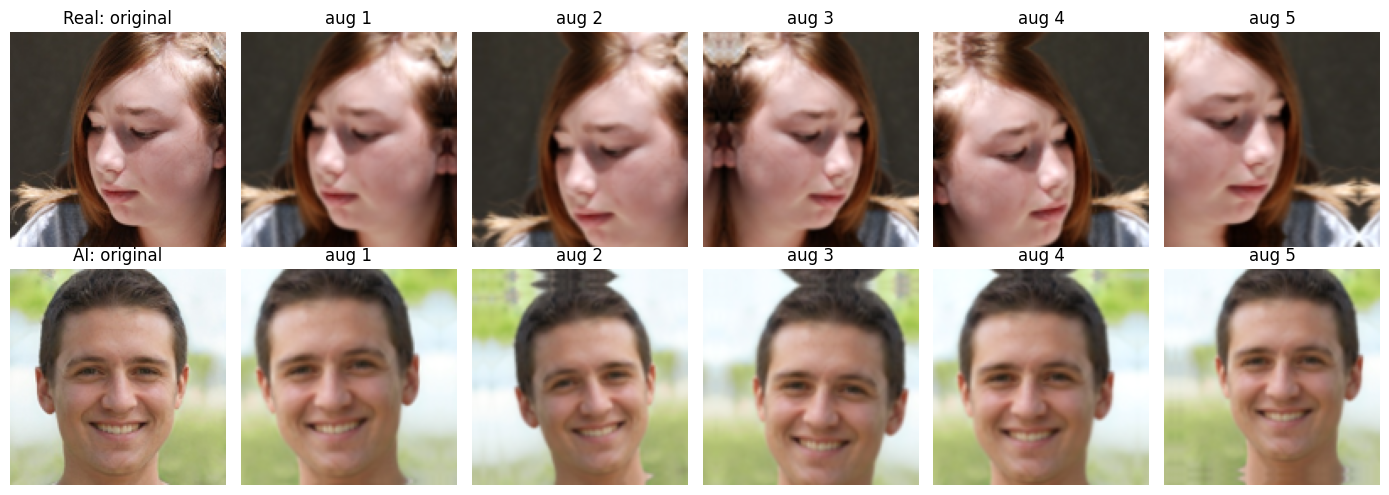

In [ ]:
# pick the first real and the first AI image in the training set
idx_real = np.where(y_train == 1)[0][0]
idx_ai   = np.where(y_train == 0)[0][0]
samples = [(X_train[idx_real], "Real"), (X_train[idx_ai], "AI")]

n_aug = 5
fig, axes = plt.subplots(2, n_aug + 1, figsize=(14, 5))

for row, (img, name) in enumerate(samples):
    # column 0: original
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"{name}: original")
    axes[row, 0].axis("off")

    # columns 1..5: augmented versions
    for col in range(1, n_aug + 1):
        aug = data_augmentation(img[None, ...], training=True)
        axes[row, col].imshow(np.clip(aug[0].numpy(), 0, 1))
        axes[row, col].set_title(f"aug {col}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

**Training the augmented CNN.** The architecture is the Part 3 CNN with the augmentation block added at the front. Changes compared with the baseline:
* An explicit `Input(shape=(128, 128, 3))` layer (Keras 3 prefers this over `input_shape=`).
* `BatchNormalization(momentum=0.9)` instead of the default 0.99. With only 32 steps per epoch, the running statistics with momentum 0.99 lag far behind (see the diagnostic below).
* The checkpoint monitors `val_accuracy` (mode `max`). Monitoring `val_loss` can select a useless epoch: in an early run it saved epoch 1, whose loss of 0.6932 = −log(0.5) belongs to a model that predicts 0.5 for every image.
* 35 epochs instead of 25, because augmented images take longer to learn.

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_12 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_70 (Activation)      │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_71 (Activation)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_72 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 96)             │         6,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 96)             │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_73 (Activation)      │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │            97 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 30,641 (119.69 KB)

 Trainable params: 30,225 (118.07 KB)

 Non-trainable params: 416 (1.62 KB)

Epoch 1/35
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4950 - loss: 0.7397
Epoch 1: val_accuracy improved from None to 0.50000, saving model to best_cnn_aug.keras

Epoch 1: finished saving model to best_cnn_aug.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.5157 - loss: 0.7410 - val_accuracy: 0.5000 - val_loss: 1.1376
Epoch 2/35
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 985ms/step - accuracy: 0.5420 - loss: 0.7174
Epoch 2: val_accuracy improved from 0.50000 to 0.51111, saving model to best_cnn_aug.keras

Epoch 2: finished saving model to best_cnn_aug.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.5294 - loss: 0.7279 - val_accuracy: 0.5111 - val_loss: 0.8001
Epoch 3/35
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 979ms/step - accuracy: 0.5638 - loss: 0.7074
Epoch 3: val_accuracy did not improve from 0.51111
32/32 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.5461 - loss: 0.7077 - val_accuracy: 0.5111 - val_loss: 0.8001
Epoch 4/35
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0

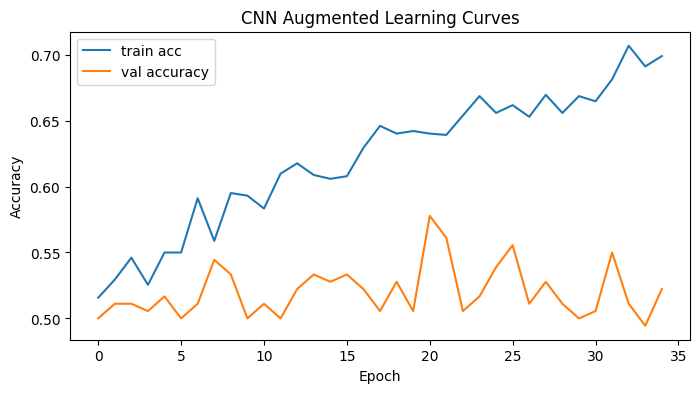

In [ ]:
# Model With Data Augmentations added

cnn_aug_model = Sequential([

    Input(shape=(128,128,3)),
    data_augmentation,

    # First conv block
    Conv2D(16, (3,3), padding='same', use_bias=False),
    BatchNormalization(momentum=0.9),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.15),

    # Second conv block
    Conv2D(32, (3,3), padding='same', use_bias=False),
    BatchNormalization(momentum=0.9),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.15),

    # Third conv block
    Conv2D(64, (3,3), padding='same', use_bias=False),
    BatchNormalization(momentum=0.9),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.15),

    GlobalAveragePooling2D(),

    Dense(96),
    BatchNormalization(momentum=0.9),
    Activation('relu'),
    Dropout(0.25),  # ← Increased final dropout

    Dense(1, activation='sigmoid')
])

cnn_aug_model.compile(optimizer= Adam(1e-3), loss = 'binary_crossentropy', metrics = ['accuracy'])
cnn_aug_model.summary()

checkpoint_cnn_aug_path = "best_cnn_aug.keras"
checkpoint_cnn_aug = ModelCheckpoint(checkpoint_cnn_aug_path, monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)


history_cnn_aug = cnn_aug_model.fit(
    X_train, y_train, validation_data=(X_val, y_val), epochs= 35, batch_size= 32, callbacks = [checkpoint_cnn_aug], verbose= 1
)

#Testing the model across epochs val data
best_val_acc_cnn_aug= np.max(history_cnn_aug.history['val_accuracy'])
best_val_loss_cnn_aug = np.min(history_cnn_aug.history['val_loss'])
best_epoch_cnn_aug = np.argmax(history_cnn_aug.history['val_accuracy'])+1
print(f">> CNN Augmented best val acc: {best_val_acc_cnn_aug:.4f} at epoch {best_epoch_cnn_aug}")

# Now Loading the best CNN Augmented Weights and evaluating on the test set
best_cnn_aug= load_model(checkpoint_cnn_aug_path)
cnn_aug_test_loss, cnn_aug_test_acc = best_cnn_aug.evaluate(X_test, y_test, verbose= 0)
print(f">> CNN Augmented test acc (best model): {cnn_aug_test_acc:.4f}")

#Plot learning curves
plt.figure(figsize=(8,4))
plt.plot(history_cnn_aug.history['accuracy'], label='train acc')
plt.plot(history_cnn_aug.history['val_accuracy'], label='val accuracy')
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("CNN Augmented Learning Curves")
plt.show()

**Diagnostic: why is validation accuracy stuck near 50%?** The training log reports accuracy in *training mode* (augmentation, dropout and batch statistics on), while validation uses *evaluation mode* (all off, BatchNorm uses running averages). This cell checks how the last-epoch model behaves in evaluation mode.

In [ ]:
# Diagnostic: is val stuck because of BatchNorm (eval mode) or weak learning?
probs = cnn_aug_model.predict(X_val, verbose=0).ravel()
print("val predictions min / mean / max:", probs.min(), probs.mean(), probs.max())
print("fraction predicted Real:", (probs >= 0.5).mean())
print("train evaluated in eval mode [loss, acc]:", cnn_aug_model.evaluate(X_train, y_train, verbose=0))

val predictions min / mean / max: 0.0060198638 0.20337377 0.82551336
fraction predicted Real: 0.07777777777777778
train evaluated in eval mode [loss, acc]: [0.8535282015800476, 0.5549019575119019]


**Diagnostic findings**
* Only 8% of validation images are predicted Real (mean prediction 0.20): the model calls almost everything AI.
* On the **training images**, accuracy is 0.555 in evaluation mode, but about 0.70 in the training log.
* Evaluation mode removes augmentation and dropout, which should make the task *easier*, yet accuracy drops. This cannot be overfitting. It points to BatchNorm: the running mean and variance used in evaluation mode do not match the batch statistics used in training.
* In an earlier run, `momentum=0.9` fixed this (validation left 50% at epoch 2 instead of epoch 11). In this final run the mismatch came back, so momentum 0.9 reduces the problem but is not a reliable fix for this small CNN.

**Comparison with the baseline.** The table shows best validation accuracy, test accuracy and the train-validation gap (averaged over the last 5 epochs). The plots overlay both models: solid lines are validation, dashed lines are training.

Model      Best val acc  Test acc  Train-val gap
CNN              0.5889    0.6700         0.1589
CNN+Aug          0.5778    0.6067         0.1720


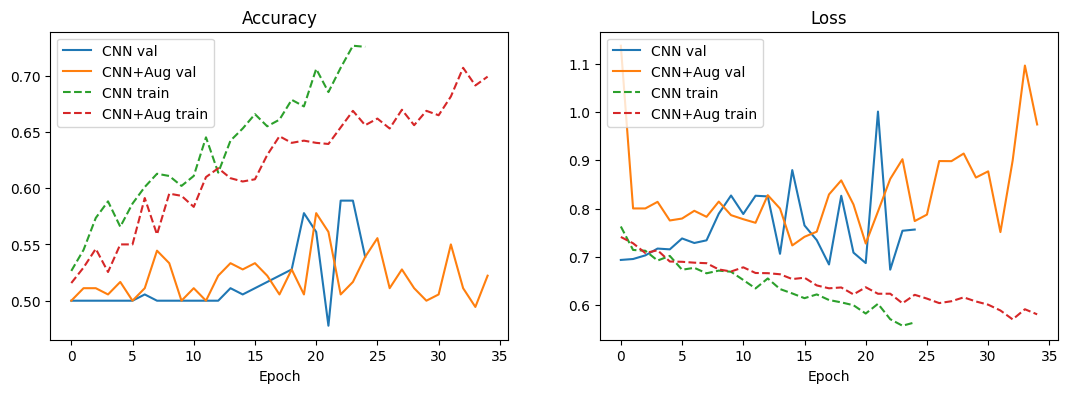

In [ ]:
# Compare baseline CNN vs CNN + augmentation
def gap(h):
    # average train-val accuracy gap over the last 5 epochs (smooths out noise)
    return np.mean(h.history['accuracy'][-5:]) - np.mean(h.history['val_accuracy'][-5:])

print(f"{'Model':<10} {'Best val acc':>12} {'Test acc':>9} {'Train-val gap':>14}")
print(f"{'CNN':<10} {best_val_acc_cnn:>12.4f} {cnn_test_acc:>9.4f} {gap(history_cnn):>14.4f}")
print(f"{'CNN+Aug':<10} {best_val_acc_cnn_aug:>12.4f} {cnn_aug_test_acc:>9.4f} {gap(history_cnn_aug):>14.4f}")

# Overlay learning curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(history_cnn.history['val_accuracy'], label='CNN val')
ax1.plot(history_cnn_aug.history['val_accuracy'], label='CNN+Aug val')
ax1.plot(history_cnn.history['accuracy'], '--', label='CNN train')
ax1.plot(history_cnn_aug.history['accuracy'], '--', label='CNN+Aug train')
ax1.set_title("Accuracy"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(history_cnn.history['val_loss'], label='CNN val')
ax2.plot(history_cnn_aug.history['val_loss'], label='CNN+Aug val')
ax2.plot(history_cnn.history['loss'], '--', label='CNN train')
ax2.plot(history_cnn_aug.history['loss'], '--', label='CNN+Aug train')
ax2.set_title("Loss"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.show()

**Part 4 conclusions**
* Train accuracy rises more slowly with augmentation (about 0.70 after 35 epochs vs 0.73 after 24 for the baseline): augmented images are harder to memorize, as expected.
* In this run, validation accuracy stays between 0.50 and 0.58 and the gap is not smaller (0.172 vs 0.159). An earlier run showed a smaller gap with augmentation (0.08 vs 0.12).
* **The effect of augmentation on this CNN is inconclusive**, because the BatchNorm mode mismatch dominates the comparison. What is consistent across runs: a 30K-parameter CNN trained from scratch on 1,020 images plateaus around 60% validation accuracy. Augmentation can limit memorization, but it cannot supply visual knowledge the model does not have. This motivates transfer learning.

## Part 5: Transfer learning with MobileNetV3Small

MobileNetV3Small, pretrained on ImageNet, is used as a frozen feature extractor, and a new classification head is trained on top. Two heads are compared on validation accuracy.

Paper: Howard et al., [Searching for MobileNetV3](https://openaccess.thecvf.com/content_ICCV_2019/html/Howard_Searching_for_MobileNetV3_ICCV_2019_paper.html), ICCV 2019.


### Approach
* **Preprocessing:** Keras MobileNetV3 has a built-in `Rescaling` layer and expects pixel values in **[0, 255]**. Our images are in [0, 1], so they are multiplied by 255 (`X_train_pp`, `X_val_pp`, `X_test_pp`). Feeding [0, 1] would not raise an error, it would just silently perform badly. Labels do not change.
* **Backbone:** `MobileNetV3Small` with ImageNet weights, `include_top=False` (drop the 1,000-class ImageNet classifier) and `pooling='avg'`, so each image becomes one 576-number feature vector.
* **Freezing:** `base.trainable = False`, so the 939,120 backbone weights stay fixed and only the new head learns. This also keeps the backbone's BatchNorm layers in inference mode with ImageNet statistics, so the Part 4 BatchNorm problem cannot happen here.
* The warning about loading 224×224 weights for a 128×128 input is expected: the backbone is fully convolutional and ends in global pooling, so it accepts other sizes.

In [ ]:
# ============================================================
# Part 5 - Transfer Learning (MobileNetV3Small)
# ============================================================
from tensorflow.keras.applications import MobileNetV3Small


# Converting back our images from range of [0,1] back to [0, 255], I.E. pre-processing them
X_train_pp = (X_train * 255.0).astype("float32")
X_val_pp = (X_val* 255.0).astype("float32")
X_test_pp= (X_test * 255.0).astype("float32")

print("X_train shape:", X_train_pp.shape)
print("X_val shape:", X_val_pp.shape)
print("X_test shape:", X_test_pp.shape)
print("Range: ", X_train_pp.min(), "to", X_train_pp.max())
print("Dtype: ", X_train_pp.dtype)


# importing MobileNet model as a frozen feature extractor
base = MobileNetV3Small(
    input_shape= (128, 128, 3),
    include_top = False, # not including the Classification layer
    weights = 'imagenet',
    pooling = 'avg'
)
base.trainable = False # freezing the weights to preserve Imagenet features

print("Output shape:", base.output_shape)
print("Number of layers:", len(base.layers))
print("Total parameters:", base.count_params())
print("Trainable weights", len(base.trainable_weights))
print("First layers:      ", [l.name for l in base.layers[:3]])


X_train shape: (1020, 128, 128, 3)
X_val shape: (180, 128, 128, 3)
X_test shape: (300, 128, 128, 3)
Range:  0.0 to 255.0
Dtype:  float32


/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Output shape: (None, 576)
Number of layers: 158
Total parameters: 939120
Trainable weights 0
First layers:       ['input_layer_17', 'rescaling_3', 'conv']


**Head A (simplest head):** Dropout(0.3) followed by Dense(1, sigmoid). Only 577 trainable parameters (576 weights + 1 bias), which makes this essentially logistic regression on ImageNet features.

In [ ]:

mobilenet_frozen = Sequential([
    Input(shape=(128, 128, 3)),
    base,
    Dropout(0.3),
    Dense(1, activation='sigmoid')

])

mobilenet_frozen.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Small (Functional)   │ (None, 576)            │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │           577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 939,697 (3.58 MB)

 Trainable params: 577 (2.25 KB)

 Non-trainable params: 939,120 (3.58 MB)

**Training Head A.** Adam with learning rate 1e-3 is fine here, because only a freshly initialized head is trained and no pretrained weights are being updated. The checkpoint keeps the epoch with the best validation accuracy.

In [ ]:
#Compiling and checkpointing and training

mobilenet_frozen.compile(optimizer= Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])


checkpoint_mobile_frozen_path = "best_mobilenet_frozen.keras"
checkpoint_mobile_frozen = ModelCheckpoint(checkpoint_mobile_frozen_path, monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)


history_mob_frozen = mobilenet_frozen.fit(
    X_train_pp, y_train,
    validation_data = (X_val_pp, y_val),
    epochs= 25,
    batch_size = 32,
    callbacks = [checkpoint_mobile_frozen]
)



Epoch 1/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.5050 - loss: 0.7974
Epoch 1: val_accuracy improved from None to 0.57778, saving model to best_mobilenet_frozen.keras

Epoch 1: finished saving model to best_mobilenet_frozen.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 19s 272ms/step - accuracy: 0.5235 - loss: 0.7554 - val_accuracy: 0.5778 - val_loss: 0.6827
Epoch 2/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.5970 - loss: 0.6757
Epoch 2: val_accuracy improved from 0.57778 to 0.62778, saving model to best_mobilenet_frozen.keras

Epoch 2: finished saving model to best_mobilenet_frozen.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 171ms/step - accuracy: 0.5902 - loss: 0.6702 - val_accuracy: 0.6278 - val_loss: 0.6561
Epoch 3/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.6634 - loss: 0.6336
Epoch 3: val_accuracy did not improve from 0.62778
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 205ms/step - accuracy: 0.6431 - loss: 0.6289 - val_accuracy: 0.6222 - val_loss: 0.6405
Epoch 4/25
32/32

>> MobileNet frozen best val acc: 0.6944 at epoch 24
>> MobileNet frozen test acc (best model): 0.7333


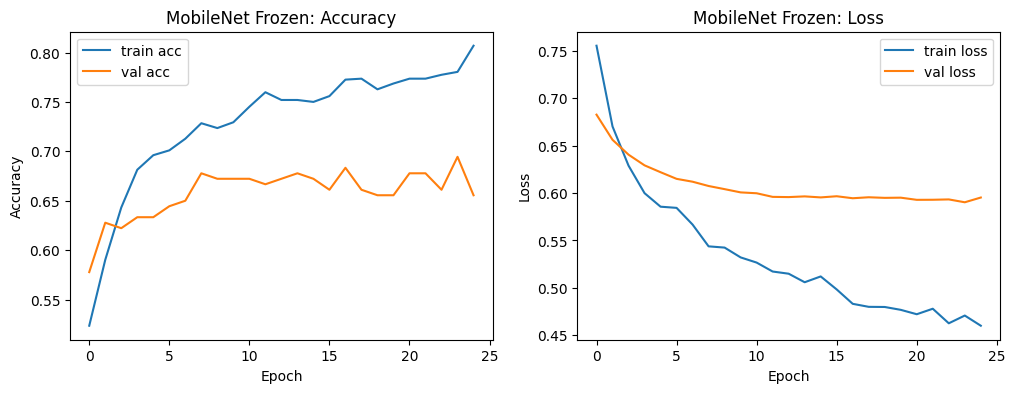

In [ ]:
# Calculating best epoch, test evaluation, learning curves
best_val_acc_mob_frozen = np.max(history_mob_frozen.history['val_accuracy'])
best_epoch_mob_frozen   = np.argmax(history_mob_frozen.history['val_accuracy']) + 1
print(f">> MobileNet frozen best val acc: {best_val_acc_mob_frozen:.4f} at epoch {best_epoch_mob_frozen}")

best_mob_frozen = load_model(checkpoint_mobile_frozen_path)
mob_frozen_test_loss, mob_frozen_test_acc = best_mob_frozen.evaluate(X_test_pp, y_test, verbose=0)
print(f">> MobileNet frozen test acc (best model): {mob_frozen_test_acc:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history_mob_frozen.history['accuracy'], label='train acc')
ax1.plot(history_mob_frozen.history['val_accuracy'], label='val acc')
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Accuracy"); ax1.set_title("MobileNet Frozen: Accuracy"); ax1.legend()

ax2.plot(history_mob_frozen.history['loss'], label='train loss')
ax2.plot(history_mob_frozen.history['val_loss'], label='val loss')
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Loss"); ax2.set_title("MobileNet Frozen: Loss"); ax2.legend()
plt.show()

**Head A results**
* Best validation accuracy 0.694 (epoch 24), test accuracy 0.733: already clearly better than every model trained from scratch.
* The curves are much smoother than for the CNNs, because the features are fixed and only 577 weights learn.
* Validation loss flattens after about epoch 20 while train loss keeps falling, so more epochs would mainly widen the gap.
* Training is fast (about 85 ms per step vs 550 ms for the CNN): the backbone only runs a forward pass, and no gradients flow through it.

**Head B (head experiment):** Dropout(0.3), Dense(128, ReLU), Dropout(0.3), Dense(1, sigmoid). 73,985 trainable parameters. Head A can only form a weighted sum of the 576 features; Head B can learn non-linear combinations of them. Everything else (backbone, optimizer, learning rate, epochs) is identical, so the head is the only difference.

In [ ]:
# Trying an alternate head

tf.random.set_seed(42)

mobilenet_frozen_b = Sequential([
    Input(shape= (128, 128, 3)),
    base,
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation = 'sigmoid')
])

mobilenet_frozen_b.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Small (Functional)   │ (None, 576)            │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,013,105 (3.86 MB)

 Trainable params: 73,985 (289.00 KB)

 Non-trainable params: 939,120 (3.58 MB)

In [ ]:
mobilenet_frozen_b.compile(optimizer= Adam(1e-3), loss='binary_crossentropy', metrics= ['accuracy'])
checkpoint_mobile_frozen_b_path = 'best_mobilenet_frozen_b.keras'
checkpoint_mobile_frozen_b= ModelCheckpoint(checkpoint_mobile_frozen_b_path, monitor='val_accuracy', save_best_only=True, mode = 'max', verbose=1 )


history_mob_frozen_b = mobilenet_frozen_b.fit(
    X_train_pp, y_train,
    validation_data = (X_val_pp, y_val),
    epochs= 25,
    batch_size= 32,
    callbacks = [checkpoint_mobile_frozen_b],
    verbose=1
)



Epoch 1/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.5404 - loss: 0.7619
Epoch 1: val_accuracy improved from None to 0.63889, saving model to best_mobilenet_frozen_b.keras

Epoch 1: finished saving model to best_mobilenet_frozen_b.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 223ms/step - accuracy: 0.5833 - loss: 0.7122 - val_accuracy: 0.6389 - val_loss: 0.6163
Epoch 2/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.6847 - loss: 0.5668
Epoch 2: val_accuracy improved from 0.63889 to 0.66667, saving model to best_mobilenet_frozen_b.keras

Epoch 2: finished saving model to best_mobilenet_frozen_b.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 207ms/step - accuracy: 0.6814 - loss: 0.5780 - val_accuracy: 0.6667 - val_loss: 0.5998
Epoch 3/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.7335 - loss: 0.5379
Epoch 3: val_accuracy improved from 0.66667 to 0.68889, saving model to best_mobilenet_frozen_b.keras

Epoch 3: finished saving model to best_mobilenet_frozen_b.keras
32/32 ━━━

Head      Trainable  Best val acc  Epoch  Test acc
A               577        0.6944     24    0.7333
B             73985        0.7556     20    0.7233


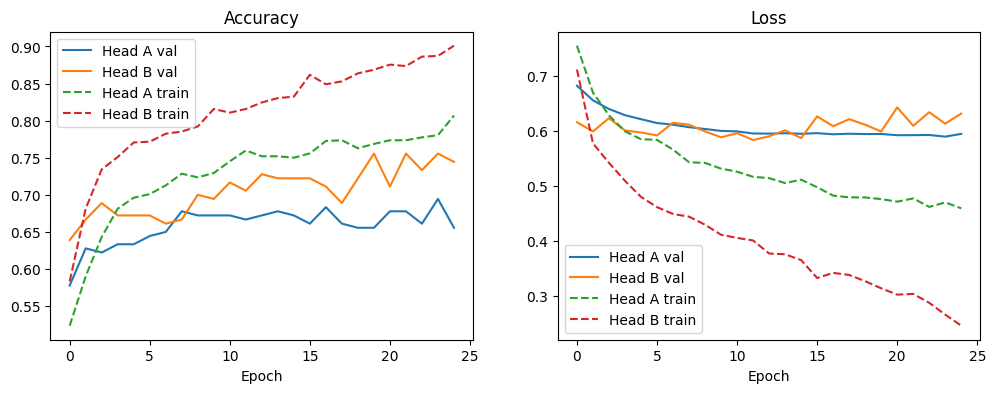

In [ ]:
best_val_acc_mob_b = np.max(history_mob_frozen_b.history['val_accuracy'])
best_epoch_mob_b   = np.argmax(history_mob_frozen_b.history['val_accuracy']) + 1
best_mob_frozen_b  = load_model(checkpoint_mobile_frozen_b_path)
mob_b_test_loss, mob_b_test_acc = best_mob_frozen_b.evaluate(X_test_pp, y_test, verbose=0)

print(f"{'Head':<8} {'Trainable':>10} {'Best val acc':>13} {'Epoch':>6} {'Test acc':>9}")
print(f"{'A':<8} {577:>10} {best_val_acc_mob_frozen:>13.4f} {best_epoch_mob_frozen:>6} {mob_frozen_test_acc:>9.4f}")
print(f"{'B':<8} {73985:>10} {best_val_acc_mob_b:>13.4f} {best_epoch_mob_b:>6} {mob_b_test_acc:>9.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history_mob_frozen.history['val_accuracy'], label='Head A val')
ax1.plot(history_mob_frozen_b.history['val_accuracy'], label='Head B val')
ax1.plot(history_mob_frozen.history['accuracy'], '--', label='Head A train')
ax1.plot(history_mob_frozen_b.history['accuracy'], '--', label='Head B train')
ax1.set_title("Accuracy"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(history_mob_frozen.history['val_loss'], label='Head A val')
ax2.plot(history_mob_frozen_b.history['val_loss'], label='Head B val')
ax2.plot(history_mob_frozen.history['loss'], '--', label='Head A train')
ax2.plot(history_mob_frozen_b.history['loss'], '--', label='Head B train')
ax2.set_title("Loss"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.show()

**Head A vs Head B**
* Head B is **consistently better on validation**: best 0.756 vs 0.694, and higher across most epochs, not only at its peak.
* On the test set the two heads are comparable (0.723 vs 0.733, a difference of 3 images out of 300).
* Head B overfits faster in loss terms (its validation loss rises while its train loss drops to about 0.25).
* **Decision:** Head B is selected as the final `mobilenet_frozen`, based on validation accuracy. The test set is not used for model selection, so the test result does not change this choice.

In [ ]:
# Setting mobilenet_frozen to be the Head B since it is better

mobilenet_frozen = best_mob_frozen_b
history_mob_frozen = history_mob_frozen_b
best_val_acc_mob_frozen = best_val_acc_mob_b
mob_frozen_test_acc = mob_b_test_acc

## Part 6: Fine-tuning MobileNetV3Small

The last layers of the backbone are unfrozen and trained together with the head at a small learning rate, so the late, ImageNet-specific features adapt to faces.


### Approach
1. **Start from the trained Part 5 model (Head B), loaded from its checkpoint file.** The head is already trained, so it sends meaningful gradients into the backbone. A random head would send large, meaningless gradients and damage the pretrained weights. Loading from file also gives a separate copy, so the Part 5 model in memory is not affected.
2. **Selective unfreezing:** only the last 30 of the 158 backbone layers are unfrozen. Early layers detect generic edges and textures that are useful for any image; late layers hold ImageNet-specific features that need to adapt to faces.
3. **BatchNorm layers stay frozen,** even inside the unfrozen part. A trainable BatchNorm layer would run in training mode and overwrite ImageNet's running statistics with statistics from batches of 32 faces. These statistics are updated by momentum, not by gradients, so a small learning rate does not protect them.
4. **Small learning rate (1e-5),** 100× smaller than in Part 5, to nudge the pretrained weights instead of overwriting them.
5. **Overfitting control:** checkpoint and EarlyStopping (patience 5, `restore_best_weights=True`), both on `val_accuracy`, plus the dropout already in Head B.

In [ ]:
# ============================================================
# Part 6 - Transfer Learning (MobileNetV3Small) + Fine-tuning
# ============================================================

# Start from Head B, which had the higher validation accuracy in Part 5
mobilenet_finetuned = load_model(checkpoint_mobile_frozen_b_path)
print([l.name for l in mobilenet_finetuned.layers])

# Exploring the layers inside the MobileNetV3Small model and then later deciding which all layers to unfreeze
base_model = mobilenet_finetuned.get_layer('MobileNetV3Small')
print([l.name for l in base_model.layers])

['MobileNetV3Small', 'dropout_27', 'dense_26', 'dropout_28', 'dense_27']
['input_layer_17', 'rescaling_3', 'conv', 'conv_bn', 'activation_74', 'expanded_conv_depthwise_pad', 'expanded_conv_depthwise', 'expanded_conv_depthwise_bn', 're_lu_42', 'expanded_conv_squeeze_excite_avg_pool', 'expanded_conv_squeeze_excite_conv', 'expanded_conv_squeeze_excite_relu', 'expanded_conv_squeeze_excite_conv_1', 're_lu_43', 'expanded_conv_squeeze_excite_mul', 'expanded_conv_project', 'expanded_conv_project_bn', 'expanded_conv_1_expand', 'expanded_conv_1_expand_bn', 're_lu_44', 'expanded_conv_1_depthwise_pad', 'expanded_conv_1_depthwise', 'expanded_conv_1_depthwise_bn', 're_lu_45', 'expanded_conv_1_project', 'expanded_conv_1_project_bn', 'expanded_conv_2_expand', 'expanded_conv_2_expand_bn', 're_lu_46', 'expanded_conv_2_depthwise', 'expanded_conv_2_depthwise_bn', 're_lu_47', 'expanded_conv_2_project', 'expanded_conv_2_project_bn', 'expanded_conv_2_add', 'expanded_conv_3_expand', 'expanded_conv_3_expand_bn

**Unfreezing.** The order matters: `base_model.trainable = True` unlocks every layer, then all but the last 30 are frozen again, then the BatchNorm layers among the last 30 are frozen again. Python slicing: `layers[:-N]` is everything except the last N, and `layers[-N:]` is the last N.

In [ ]:
# Unfreezing the layers

N= 30 # Unfreezing the last 30 layers from base_model (MobileNet)

base_model.trainable = True

for layer in base_model.layers[:-N]: # Freezing all except last 30 layers
    layer.trainable = False

for layer in base_model.layers[-N:]: # For last 30 layers, if it is BatchNormalisation, freeze them back
    if isinstance(layer, BatchNormalization):
      layer.trainable = False

print("Trainable layers in backbone: ", sum([layer.trainable for layer in base_model.layers]))
print("BN layers in last N:", sum(isinstance(l, BatchNormalization) for l in base_model.layers[-N:]))

# Printing last N layers
# print("Unfrozen layers:")
# for layer in base_model.layers[-N:]:
#   print(f" {layer.name:<40} trainable= {layer.trainable}")x

Trainable layers in backbone:  24
BN layers in last N: 6


**Result:** 24 trainable layers = the last 30 layers minus the 6 BatchNorm layers inside them.

**Fine-tuning.** The model must be **recompiled** after changing `trainable`, because Keras fixes the list of weights to update at compile time. The summary shows 642,785 trainable parameters: 73,985 in the head plus 568,800 in the unfrozen backbone layers (the last 30 layers hold about 60% of the backbone weights, because late layers have many channels).

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

mobilenet_finetuned.compile(optimizer = Adam(1e-5), loss = 'binary_crossentropy', metrics = ['accuracy'])

mobilenet_finetuned.summary()


checkpoint_mobile_finetuned_path = 'best_mobilenet_finetuned.keras'
checkpoint_mobile_finetuned = ModelCheckpoint(checkpoint_mobile_finetuned_path, monitor = 'val_accuracy', save_best_only=True, mode = 'max', verbose = 1)

# Using earlystopper to stop in case there isn't any improvement in mmy val_loss
early_stop_finetuned = EarlyStopping(monitor='val_accuracy', mode = 'max', patience=5, restore_best_weights=True, verbose=1)

history_mob_finetuned = mobilenet_finetuned.fit(
    X_train_pp, y_train,
    validation_data = (X_val_pp, y_val),
    batch_size = 32,
    epochs = 20,
    callbacks = [checkpoint_mobile_finetuned, early_stop_finetuned],
    verbose =1
)



Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Small (Functional)   │ (None, 576)            │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,013,105 (3.86 MB)

 Trainable params: 642,785 (2.45 MB)

 Non-trainable params: 370,320 (1.41 MB)

Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.8890 - loss: 0.2770
Epoch 1: val_accuracy improved from None to 0.76111, saving model to best_mobilenet_finetuned.keras

Epoch 1: finished saving model to best_mobilenet_finetuned.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 17s 278ms/step - accuracy: 0.8765 - loss: 0.2901 - val_accuracy: 0.7611 - val_loss: 0.5875
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.8858 - loss: 0.2879
Epoch 2: val_accuracy improved from 0.76111 to 0.76667, saving model to best_mobilenet_finetuned.keras

Epoch 2: finished saving model to best_mobilenet_finetuned.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 216ms/step - accuracy: 0.8814 - loss: 0.2960 - val_accuracy: 0.7667 - val_loss: 0.5850
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.9081 - loss: 0.2567
Epoch 3: val_accuracy did not improve from 0.76667
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 224ms/step - accuracy: 0.8941 - loss: 0.2724 - val_accuracy: 0.7667 - val_loss: 0.5848
Epo

Model                   Best val acc  Test acc
MobileNet frozen (B)          0.7556    0.7233
MobileNet fine-tuned          0.7778    0.7633


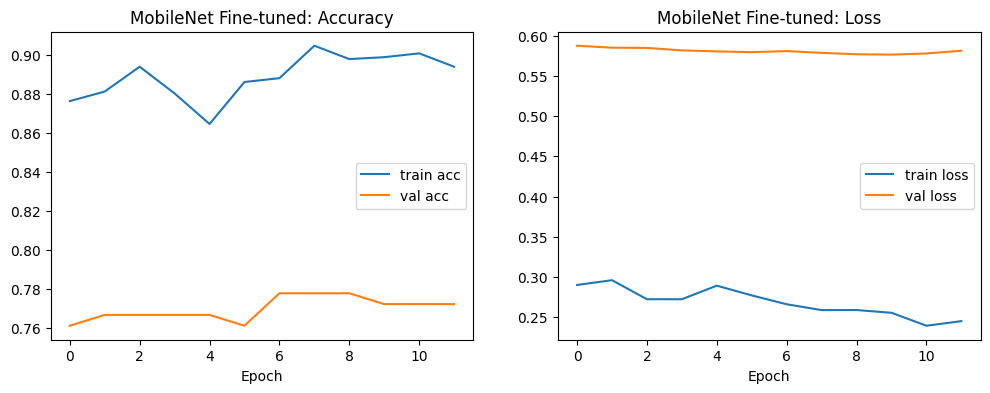

In [ ]:
best_val_acc_mob_ft = np.max(history_mob_finetuned.history['val_accuracy'])
best_epoch_mob_ft   = np.argmax(history_mob_finetuned.history['val_accuracy']) + 1
best_mob_ft = load_model(checkpoint_mobile_finetuned_path)
mob_ft_test_loss, mob_ft_test_acc = best_mob_ft.evaluate(X_test_pp, y_test, verbose=0)

print(f"{'Model':<22} {'Best val acc':>13} {'Test acc':>9}")
print(f"{'MobileNet frozen (B)':<22} {best_val_acc_mob_b:>13.4f} {mob_b_test_acc:>9.4f}")
print(f"{'MobileNet fine-tuned':<22} {best_val_acc_mob_ft:>13.4f} {mob_ft_test_acc:>9.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history_mob_finetuned.history['accuracy'], label='train acc')
ax1.plot(history_mob_finetuned.history['val_accuracy'], label='val acc')
ax1.set_xlabel("Epoch"); ax1.set_title("MobileNet Fine-tuned: Accuracy"); ax1.legend()
ax2.plot(history_mob_finetuned.history['loss'], label='train loss')
ax2.plot(history_mob_finetuned.history['val_loss'], label='val loss')
ax2.set_xlabel("Epoch"); ax2.set_title("MobileNet Fine-tuned: Loss"); ax2.legend()
plt.show()

**Part 6 results**
* Best validation accuracy 0.778 (epoch 7), test accuracy **0.763**, the best of all models. Early stopping ended training at epoch 12 and restored epoch 7.
* Epoch 1 already matched the frozen model, so there was no disruption of the pretrained features: frozen BatchNorm and the small learning rate did their job.
* Validation loss stays nearly flat (about 0.58) while train accuracy reaches 0.90. At learning rate 1e-5 the weights move very little, and much of what they learn fits the training images.
* Compared with frozen Head B: +2 points on validation and +4 points on test. Part 7 shows where the gain comes from: fine-tuning catches 12 more AI faces while recognizing the same number of real faces.
* Lesson from development: an earlier attempt paired `EarlyStopping(monitor='val_loss')` with `mode='max'`. It treated rising loss as improvement, stopped while the model was improving, and restored the worst epoch. Monitor and mode must agree.

## Part 7: Model comparison and analysis

All five models on the same test set: an accuracy bar chart, confusion matrices, and sample predictions grouped by how many models get them right. Five questions guide the analysis:
1. Which model performs best on the test set?
2. Which model has the smallest train-validation gap?
3. Do certain models favour precision or recall?
4. What types of faces fool all models?
5. When models disagree, which one is usually right?


### Overview
The first cell collects all five models with **the input each one needs** (MLP and CNNs take `X_test` in [0, 1]; both MobileNets take `X_test_pp` in [0, 255]) and predicts on the test set once. The sanity check recomputes each test accuracy from the predictions; every pair must match, which confirms that each model received the right input and weights.

In [ ]:
# ============================================================
# Part 7 - Model Comparison & Analysis
# ============================================================

# name: (model, test input, best val acc, test acc)

models_info = {
    "MLP": (mlp_model, X_test, best_val_acc_mlp, mlp_test_acc),
    "CNN": (best_cnn, X_test, best_val_acc_cnn, cnn_test_acc),
    "CNN+Aug": (best_cnn_aug, X_test, best_val_acc_cnn_aug, cnn_aug_test_acc),
    "MobileNet": (mobilenet_frozen, X_test_pp, best_val_acc_mob_frozen, mob_frozen_test_acc),
    "MobileNet-FT": (mobilenet_finetuned, X_test_pp, best_val_acc_mob_ft, mob_ft_test_acc)
}


probs = {}

for name, (model, X, _, _) in models_info.items():
  probs[name] = model.predict(X, verbose=0).ravel()


preds = {name: (p>= 0.5).astype(int) for name, p in probs.items()}

# sanity check: accuracy recomputed from predictions must match the stored test accuracy
for name in models_info:
    print(f"{name:<13} recomputed: {np.mean(preds[name] == y_test):.4f}   stored: {models_info[name][3]:.4f}")

MLP           recomputed: 0.6667   stored: 0.6667
CNN           recomputed: 0.6700   stored: 0.6700
CNN+Aug       recomputed: 0.6067   stored: 0.6067
MobileNet     recomputed: 0.7233   stored: 0.7233
MobileNet-FT  recomputed: 0.7633   stored: 0.7633


**Grouped bar chart:** best validation accuracy (blue) and test accuracy (orange) per model, with the 50% chance level as a dashed line. The axis starts at 0 so that differences are not exaggerated.

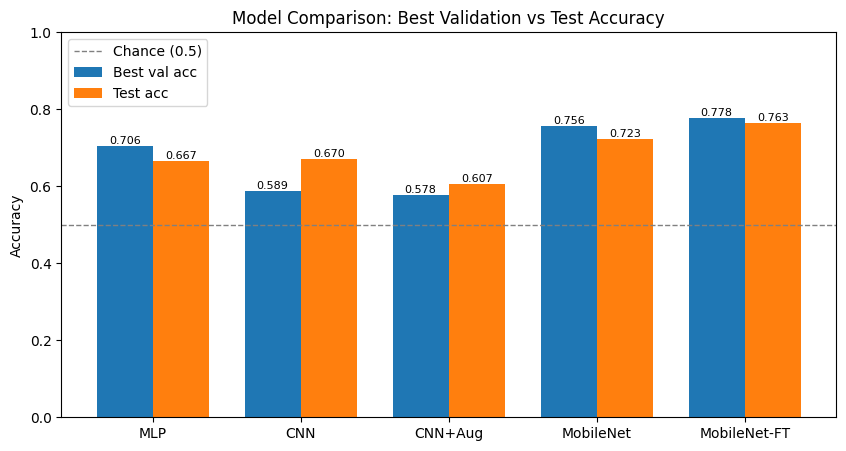

In [ ]:
names     = list(models_info)
val_accs  = [models_info[n][2] for n in names]
test_accs = [models_info[n][3] for n in names]

x = np.arange(len(names))   # positions 0..4, one group per model
w = 0.38                    # width of each bar

fig, ax = plt.subplots(figsize=(10, 5))
bars_val  = ax.bar(x - w/2, val_accs,  w, label='Best val acc', color='tab:blue')
bars_test = ax.bar(x + w/2, test_accs, w, label='Test acc',     color='tab:orange')
ax.bar_label(bars_val,  fmt='%.3f', fontsize=8)
ax.bar_label(bars_test, fmt='%.3f', fontsize=8)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Chance (0.5)')

ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylim(0, 1); ax.set_ylabel("Accuracy")
ax.set_title("Model Comparison: Best Validation vs Test Accuracy")
ax.legend(loc='upper left')
plt.show()

**Confusion matrices** for all five models on the test set (rows = true class, columns = predicted class). The printout below the grid breaks accuracy down per class, to check whether a model is biased toward one class.

In [ ]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()                       # 2x3 grid -> flat list of 6 axes

for ax, name in zip(axes, names):
    cm = confusion_matrix(y_test, preds[name], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['AI', 'Real'], yticklabels=['AI', 'Real'])
    ax.set_title(f"{name} (test acc {models_info[name][3]:.3f})")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")

axes[-1].axis('off')                      # 5 models, 6 slots: hide the empty one
plt.tight_layout()
plt.show()

# per-class breakdown: is any model biased toward one class?
for name in names:
    cm = confusion_matrix(y_test, preds[name], labels=[0, 1])
    ai_correct   = cm[0, 0] / cm[0].sum()
    real_correct = cm[1, 1] / cm[1].sum()
    print(f"{name:<13} AI correct: {ai_correct:.2f}   Real correct: {real_correct:.2f}   "
          f"predicted Real: {preds[name].mean():.2f}")

**What the confusion matrices show**
* MLP and CNN are balanced but weak (about 47 to 53 mistakes in each direction).
* CNN+Aug catches only 51% of AI faces (a coin flip on that class); most of its accuracy comes from real faces.
* Frozen MobileNet recognizes 81% of real faces but only 64% of AI faces. ImageNet features describe natural photographs well, but were never trained to notice generation artifacts.
* **Fine-tuning's entire gain comes from the AI class:** real faces recognized stay at 121, while AI faces caught rise from 96 to 108. Unfreezing the late layers let the network learn AI-specific cues.
* For the best models the dominant error is an AI face accepted as real, which is the more costly mistake for a detector.

**Sample predictions.** The test images are first grouped by how many of the five models classify them correctly (all correct, disagreement, all wrong), then 3 + 4 + 3 images are sampled with a fixed seed. Each panel shows the image index, the true label (T:0 = AI, T:1 = Real), and every model's P(Real) with its prediction: green = correct, red = wrong. Disagreement images are marked in bold.

In [ ]:
label_name = {0: "AI", 1: "Real"}

# which models got each image right: shape (5 models, 300 images)
correct   = np.array([preds[n] == y_test for n in names])
n_correct = correct.sum(axis=0)          # per image: how many of the 5 models were right

all_right = np.where(n_correct == 5)[0]
all_wrong = np.where(n_correct == 0)[0]
disagree  = np.where((n_correct > 0) & (n_correct < 5))[0]
print(f"all correct: {len(all_right)}   disagree: {len(disagree)}   all wrong: {len(all_wrong)}")

rng = np.random.default_rng(42)
def pick(idx, k):
    return rng.choice(idx, size=min(k, len(idx)), replace=False)

sel = np.concatenate([pick(all_right, 3), pick(disagree, 4), pick(all_wrong, 3)])

fig, axes = plt.subplots(2, 5, figsize=(18, 11))
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(X_test[i]); ax.axis('off')
    tag = "ALL CORRECT" if n_correct[i] == 5 else ("ALL WRONG" if n_correct[i] == 0 else "DISAGREE")
    ax.set_title(f"#{i}   T:{y_test[i]} ({label_name[y_test[i]]})\n{tag}", fontsize=10,
                 fontweight='bold' if tag == "DISAGREE" else 'normal')
    for k, name in enumerate(names):
        p = probs[name][i]
        color = 'green' if preds[name][i] == y_test[i] else 'red'
        ax.text(0.0, -0.05 - 0.08 * k, f"{name}: {p:.2f} → {label_name[preds[name][i]]}",
                transform=ax.transAxes, color=color, fontsize=9, va='top')

plt.subplots_adjust(hspace=0.75)
plt.show()

**Numbers for the analysis questions:** the train-validation gap at each model's selected epoch (Q2), precision and recall with AI as the detected class (Q3), accuracy on the disagreement images, and a majority vote of all five models (Q5).

In [ ]:
# ---- Q2: train-validation gap at the best (selected) epoch ----
hists = {"MLP": history_mlp, "CNN": history_cnn, "CNN+Aug": history_cnn_aug,
         "MobileNet": history_mob_frozen, "MobileNet-FT": history_mob_finetuned}
print("Q2  Train-val gap at best-val epoch")
for name, h in hists.items():
    e = np.argmax(h.history['val_accuracy'])
    print(f"  {name:<13} train {h.history['accuracy'][e]:.3f}  val {h.history['val_accuracy'][e]:.3f}  "
          f"gap {h.history['accuracy'][e] - h.history['val_accuracy'][e]:+.3f}  (epoch {e+1})")

# ---- Q3: precision and recall, with "AI" as the class being detected ----
print("\nQ3  Detecting AI faces")
for name in names:
    cm = confusion_matrix(y_test, preds[name], labels=[0, 1])
    tp, fn = cm[0, 0], cm[0, 1]      # AI caught, AI missed
    fp     = cm[1, 0]                # real flagged as AI
    print(f"  {name:<13} precision {tp/(tp+fp):.2f}   recall {tp/(tp+fn):.2f}")

# ---- Q5: on the disagreement images, how often is each model right? ----
print(f"\nQ5  Accuracy on the {len(disagree)} disagreement images")
for k, name in enumerate(names):
    print(f"  {name:<13} {correct[k, disagree].mean():.2f}")
majority = (np.array([preds[n] for n in names]).sum(axis=0) >= 3).astype(int)
print(f"\n  Majority vote of all 5 models, full test set: {np.mean(majority == y_test):.4f}")

### Analysis

**1. Which model performs best on the test set?**
The fine-tuned MobileNetV3Small (0.763 test, 0.778 validation), followed by the frozen MobileNet (0.723). Both transfer-learning models beat every model trained from scratch by roughly 5 to 15 points. Among MLP, CNN and CNN+Aug the ordering is within noise and changed between runs.

**2. Which model has the smallest train-validation gap?**
CNN+Aug (+0.062 at its selected epoch), but mainly because its training accuracy is low, not because it generalizes well. The accurate models have similar gaps (about +0.11); the MobileNets combine that gap with much higher validation accuracy.

**3. Do certain models favor precision vs. recall?** (AI treated as the detected class)
MLP and CNN are balanced (about 0.66 each). Both MobileNets favor **precision**: when they flag a face as AI they are right 77 to 79% of the time, but they miss many fakes (frozen recall 0.64). CNN+Aug has the lowest recall (0.51). Fine-tuning improved recall the most (0.64 to 0.72).

**4. What types of faces fool all models?**
8 of the 300 test images fool all five models. The examples shown are AI faces classified as Real, some with high confidence (up to 0.97): photorealistic faces with natural backgrounds and lighting. At 128×128 resolution, fine generation artifacts are likely lost to downsampling.

**5. When models disagree, which one is usually right?**
Only 77 images (26%) are classified correctly by all models, while 215 (72%) split them. On those disagreement images the fine-tuned MobileNet is right most often (0.71), then the frozen MobileNet (0.65); MLP and CNN are near 0.57 and CNN+Aug is at chance (0.49). The MobileNets are not always right: some images are solved by the small models and missed by both MobileNets. A majority vote of all five models reaches 0.737, **below** the fine-tuned MobileNet alone, because the three weaker models outvote the two stronger ones.

## Part 8: Interactive game, human vs model

A Gradio app in which a person and the fine-tuned model guess Real or AI on the same held-out test faces.


### Implementation
The Gradio app runs locally with `demo.launch()` at `localhost:7860`.

**Files (in `game/`, outside this notebook):**
* `app.py`: the Gradio game (built with `gr.Blocks`, Gradio 6).
* `best_model.keras`: the fine-tuned MobileNetV3Small from Part 6.
* `test_images/real/` and `test_images/ai/`: 20 + 20 held-out test images saved as PNG, so the pixels match exactly what the model was evaluated on. The folder name gives the true label.
* `requirements.txt`: `tensorflow==2.20.0`, `keras==3.13.2`, `gradio==6.28.0`, `numpy`, `pillow` (TensorFlow and Keras pinned to the versions used in Colab, so the saved model loads).

**Game features:** a face from the test set each round; **Real** and **AI-generated** buttons; the model's prediction with its confidence; live scores for human and model; a round counter with a progress bar; feedback revealing the correct answer; and a final summary after 10 rounds showing who won.

**Local check:** before building the game, the saved model was loaded in a local Python 3.12 virtual environment and scored 0.78 on the 40 game images, consistent with its 0.763 test accuracy. This confirmed that the app uses the same preprocessing as training (RGB, 128×128, float32, **no** division by 255).